# Multivariable calculus 3: Optimization

*Learning path: multivariable calculus, part 3 of 7.* [Index](README.md) · Previous: [Partial derivatives and the gradient](02-partial-derivatives-and-gradient.ipynb) · Next: [Lagrange multipliers](04-lagrange-multipliers.ipynb)

Given five measured points that almost lie on a line, which line fits them best? A company makes two products that
compete with each other; which prices bring the most profit? Both are questions of the form *where is this function
smallest (or largest)?* In one variable you set $f'(x) = 0$. This lesson does the same with several variables and
learns to tell a peak from a pit from a pass.

**Who this is for.** You know partial derivatives and the gradient ([lesson 2](02-partial-derivatives-and-gradient.ipynb))
and how to find extremes of a function of one variable ([foundations 7](../foundations/07-calculus.ipynb)). Lesson 1's
pictures of peaks, pits and saddles help.

**What you will be able to do afterwards:**

1. find the critical points of $f(x, y)$ by solving $\nabla f = 0$;
2. classify them with the second derivative test, and explain the test with the Hessian matrix;
3. find the best-fitting line through data points as a minimization (least squares);
4. say when a numeric search is needed, and what it can and can't promise.

Plan about an hour.

## 1. Warm-up in one variable

On a closed interval $[a, b]$ a continuous function reaches its maximum and minimum, either where $f'(x) = 0$ or at
an end point. For $f(x) = x^3 - 3x$ on $[-3, 2]$: $f'(x) = 3x^2 - 3 = 0$ at $x = \pm 1$, and the candidates are

| $x$ | $-3$ | $-1$ | $1$ | $2$ |
|---|---|---|---|---|
| $f(x)$ | $-18$ | $2$ | $-2$ | $2$ |

The minimum is $-18$ at $x = -3$, an end point. `minimize(f, x, a, b)` does exactly this; its note lists the
candidates:

In [1]:
minimize(x^3 - 3*x, x, -3, 2)

-3

> Closed interval method: a continuous f on [-3, 2] takes its minimum at a critical point (f' = 0) or at an end point. Candidates:
>
> - x = -3: f = -18
> - x = 2: f = 2
> - x = 1: f = -2
> - x = -1: f = 2
>
> The minimum is f = -18 at x = -3.

**Try this.** Use `maximize` on the same interval. The largest value, 2, is reached twice; which $x$ does Galileo
return, and what does its note say about the other one?

## 2. Critical points

At the top of a smooth hill the ground is level in every direction: all directional derivatives are 0, so
$\nabla f = [0, 0]$. A point where the gradient is zero is a **critical point**. Peaks, pits and passes are all
critical points.

Take $f(x, y) = x^3 - 3xy + y^3$ from lesson 1's exercise. By hand:

$$f_x = 3x^2 - 3y = 0, \qquad f_y = -3x + 3y^2 = 0.$$

The first gives $y = x^2$; put it in the second: $-3x + 3x^4 = 0$, so $x(x^3 - 1) = 0$, $x = 0$ or $x = 1$. The
critical points are $(0, 0)$ and $(1, 1)$. Galileo:

In [2]:
f = x^3 - 3*x*y + y^3
critical(f, [x y])

x^3-3*x*y+y^3

[0, 0;
 1, 1]

> Critical points are where every partial derivative is 0 (grad f = 0); Galileo solved 3*x^2-3*y = 0, 3*y^2-3*x = 0 and lists the real solutions, one per row. The second-derivative test (classify) says:
>
> - (0, 0): f = 0, saddle point
> - (1, 1): f = -1, local minimum

`critical(f, [x y])` solves $\nabla f = 0$ and returns the real solutions, one per row. For polynomials it is exact:
it eliminates unknowns one at a time, as you did by hand. Its note already says which is which; let us see why.

**Try this.** Find the critical points of $g(x, y) = x^2 + xy + y^2 - 3x$ by hand (it is a linear system), then check
with `critical`.

## 3. The second derivative test

Near a critical point the tangent plane is flat, so the shape is decided by the **second** derivatives. They form
the **Hessian matrix**

$$H = \begin{bmatrix} f_{xx} & f_{xy} \\ f_{yx} & f_{yy} \end{bmatrix},$$

and near the critical point $p$, with a small step $h = [h_1, h_2]$,

$$f(p + h) \approx f(p) + \tfrac12\, h^T H h.$$

So everything depends on the sign of the quadratic form $h^T H h$:

* positive for every direction $h$: $f$ goes up in every direction, a **minimum**;
* negative for every $h$: a **maximum**;
* positive for some $h$ and negative for others: a **saddle**.

Linear algebra decides this with eigenvalues: all positive, all negative, or mixed. For two variables that is the
same as looking at $D = f_{xx}f_{yy} - f_{xy}^2$ (the determinant, the product of the eigenvalues) and the sign of
$f_{xx}$.

In [3]:
H = hessian(f, [x y])

[6*x,  -3;
  -3, 6*y]

> The Hessian holds the second partial derivatives ∂²f/∂x_i∂x_j; it is symmetric when they are continuous. At a critical point it decides the shape: all eigenvalues positive means a minimum, all negative a maximum, mixed signs a saddle (classify does this).

At $(0, 0)$: $H = \begin{bmatrix} 0 & -3 \\ -3 & 0 \end{bmatrix}$, $D = -9 < 0$: a saddle. At $(1, 1)$:
$H = \begin{bmatrix} 6 & -3 \\ -3 & 6 \end{bmatrix}$, $D = 27 > 0$ and $f_{xx} = 6 > 0$: a minimum. `classify` does the
test at a point; with `explain = "teach"` its note also shows $D$ with the numbers:

In [4]:
explain = "teach"
classify(f, [x y], [0 0])
classify(f, [x y], [1 1])
explain = "brief"

"teach"
"saddle"

> The Hessian at (0, 0) is [0, -3; -3, 0] with eigenvalues -3.0, 3.0. All positive: the graph curves up in every direction (minimum). All negative: maximum. Both signs: a saddle. A zero eigenvalue leaves the test inconclusive.
>
> With two variables the same test reads: D = f_xx f_yy − f_xy² = 0 · 0 − (-3)² = -9. D > 0 and f_xx > 0: minimum; D > 0 and f_xx < 0: maximum; D < 0: saddle; D = 0: inconclusive.

"min"

> The Hessian at (1, 1) is [6, -3; -3, 6] with eigenvalues 3.0, 9.0. All positive: the graph curves up in every direction (minimum). All negative: maximum. Both signs: a saddle. A zero eigenvalue leaves the test inconclusive.
>
> With two variables the same test reads: D = f_xx f_yy − f_xy² = 6 · 6 − (-3)² = 27. D > 0 and f_xx > 0: minimum; D > 0 and f_xx < 0: maximum; D < 0: saddle; D = 0: inconclusive.

"brief"

And on the map: the X-shaped crossing at the origin, closed curves around $(1, 1)$:

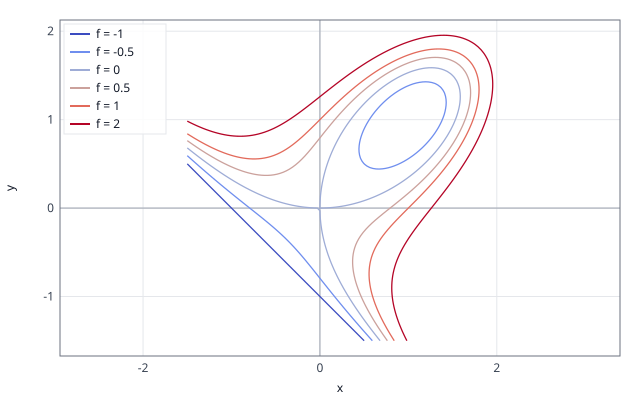

> Level curves of f: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [5]:
contour(f, x, -1.5, 2, y, -1.5, 2, [-1 -0.5 0 0.5 1 2])

**When the test says nothing.** For $x^4 + y^4$ and $x^4 - y^4$ the Hessian at the origin is the zero matrix: the
test is inconclusive, yet the first has a minimum and the second a saddle. You must look closer (slices!).

**Try this.** Classify the critical points of $g(x, y) = x^2 + xy + y^2 - 3x$ from section 2 by computing $D$ by hand,
then with `classify`.

## 4. Fitting a line: least squares

Five measurements, perhaps the stretch $y$ (cm) of a spring under a load $x$ (kg), one row per measurement:

[1,  2.1;
 2,  3.9;
 3,  6.2;
 4,  7.8;
 5, 10.1]

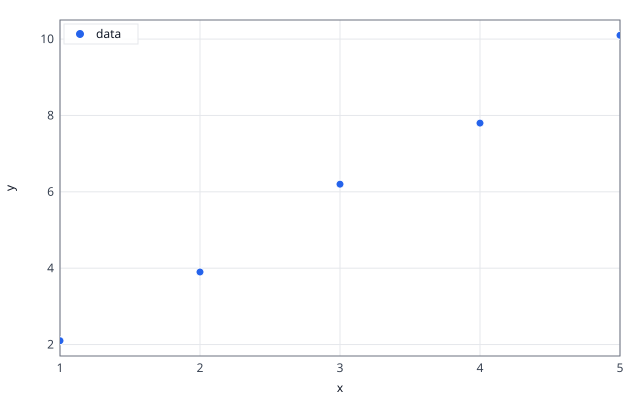

> `scatter`: Plots observations as points.

In [6]:
D = [1 2.1; 2 3.9; 3 6.2; 4 7.8; 5 10.1]
scatter(D, [x y])

We want the line $y = mx + b$ that fits best. "Best" here means: the sum of the squared vertical errors,

$$E(m, b) = \sum_{i} (y_i - m x_i - b)^2,$$

is as small as possible. That is a function of **two** variables, $m$ and $b$: a bowl. Build it and find its
critical point:

In [7]:
E = sum((D[k, 1] - m*D[k, 0] - b)^2, k, 0, 4)
critical(E, [m b])

5*(b^2+6*b*m-12.04*b+11*m^2-44.08*m+44.182)

> `sum`: Sum or product of f for k = a, a+1, ..., b; sum(A) adds the entries of a matrix.

[1.99, 0.05]

> Critical points are where every partial derivative is 0 (grad f = 0); Galileo solved 5*(6*b+22*m-44.08) = 0, 10*(b+3*m-6.02) = 0 and lists the real solutions, one per row. The second-derivative test (classify) says:
>
> - (1.99, 0.05): f = 0.107, local minimum

Rows and columns are counted from 0, so `D[k, 0]` is the load and `D[k, 1]` the stretch of measurement $k$. The
best line is $y = 1.99x + 0.05$, very close to $y = 2x$: the spring stretches 2 cm per kg. Setting
$\partial E/\partial m = \partial E/\partial b = 0$ by hand gives two linear equations, the **normal equations**;
every statistics package solves them for you. Look at the fit:

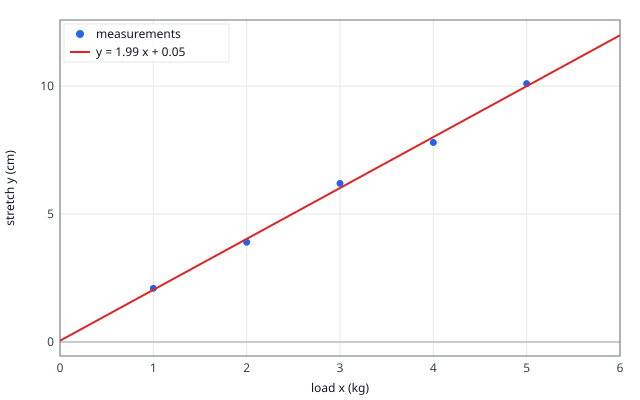

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = show(scatter(D, [x y]), plot(1.99*x + 0.05, x, 0, 6));
labels(legend(p, "measurements", "y = 1.99 x + 0.05"), "load x (kg)", "stretch y (cm)")

**Try this.** Write $\partial E/\partial b = 0$ out by hand for general data and show it says $\bar y = m \bar x + b$:
the best line passes through the average point $(\bar x, \bar y)$. Check it with the numbers above.

## 5. When there is no formula: numeric search

$f(x, y) = (1 - x)^2 + 100(y - x^2)^2$, the Rosenbrock function, has its minimum at $(1, 1)$ at the bottom of a long,
curved, nearly flat valley. It is a standard test for minimization methods. `critical` would find the point, but in
real problems the equations $\nabla f = 0$ usually can't be solved exactly. Then we search: start somewhere, and
walk downhill.

In [9]:
minimize((1 - x)^2 + 100*(y - x^2)^2, [x y], [-1.2 1])

[1.0, 1.0]

> Numeric search (BFGS: steps downhill along the gradient, learning the curvature as it goes) from (-1.2, 1.0) reached a local minimum after 35 steps: f = 0.0 at x = 1.0, y = 1.0. Another start can find another local minimum.

How to read the call: `minimize(f, [x y], [x0 y0])` starts at $(x_0, y_0)$ and uses BFGS, a refinement of "walk
against the gradient" that learns the curvature of $f$ as it goes, so it can follow the bending valley. Its note
gives the number of steps, here a few dozen: the search has to creep along the curved valley floor. The start
$(-1.2, 1)$ is the traditional one for this test. See the valley:

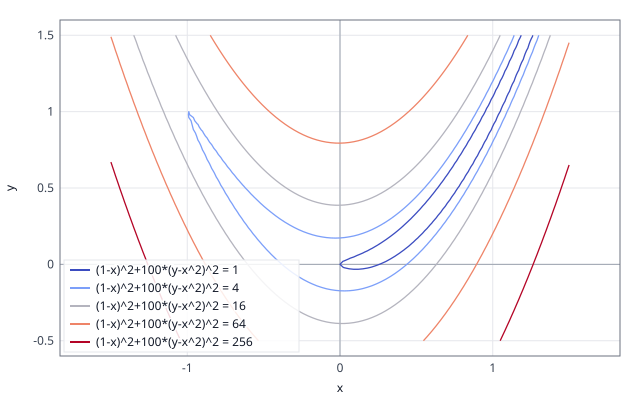

> Level curves of (1-x)^2+100*(y-x^2)^2: each curve joins the points where f has one value (the legend gives it), from blue (low) to red (high). Where curves crowd together f changes fast; the gradient crosses them at right angles.

In [10]:
contour((1 - x)^2 + 100*(y - x^2)^2, x, -1.5, 1.5, y, -0.5, 1.5, [1 4 16 64 256])

A numeric search only promises a **local** minimum near where it started. A function with many pits needs several
starts, and even then there is no guarantee. With $\sin x \sin y$, which has a pit every $2\pi$:

In [11]:
minimize(sin(x)*sin(y), [x y], [1 -1])
minimize(sin(x)*sin(y), [x y], [4 1])
minimize(sin(x)*sin(y), [x y], [1 1])

[1.570796327, -1.570796327]

> Numeric search (BFGS: steps downhill along the gradient, learning the curvature as it goes) from (1.0, -1.0) reached a local minimum after 5 steps: f = -1 at x = 1.5707963268, y = -1.5707963268. Another start can find another local minimum.

[4.71238898, 1.570796327]

> Numeric search (BFGS: steps downhill along the gradient, learning the curvature as it goes) from (4.0, 1.0) reached a local minimum after 6 steps: f = -1 at x = 4.7123889804, y = 1.5707963268. Another start can find another local minimum.

[0.0, 0.0]

> Numeric search (BFGS: steps downhill along the gradient, learning the curvature as it goes) from (1.0, 1.0) reached a local minimum after 5 steps: f = 0.0 at x = 0.0, y = 0.0. Another start can find another local minimum. Careful: the second-derivative test at this point gives "saddle point", not a local minimum: the search stopped where the gradient is 0. Try another start.

The first two starts find two different minima, $(\pi/2, -\pi/2)$ and $(3\pi/2, \pi/2)$, both with value $-1$. The
third start is a trap: from $(1, 1)$ the downhill direction runs along the diagonal $y = x$ straight into the saddle
at the origin, where the gradient is 0 and the search stops. Read the note: Galileo checks the point with the second
derivative test and warns you. A gradient of 0 is not enough; the second derivative test of section 3 is what tells a minimum.

## 6. Global extremes on a closed region

On a closed and bounded region (a disk, a rectangle) a continuous $f$ has a largest and a smallest value, and as in
section 1 they occur at critical points **inside** or somewhere **on the boundary**. The boundary is a curve, so
the problem there has one variable less. The next lesson gives a better tool for the boundary: Lagrange multipliers.

## Exercises

1. **Classify.** Find and classify all critical points of $f(x, y) = x^4 + y^4 - 4xy$ by hand. Check with
   `critical` and `classify`, and draw the contour map.
2. **A box.** A box without a lid must hold 32 liters (32 000 cm³). Write its surface area as a function of the base
   sides $x$, $y$ (the height is $32000/(xy)$), and find the dimensions that use the least cardboard.
3. **Through the origin.** For the spring data, fit a line through the origin, $y = mx$: minimize
   $E(m) = \sum (y_i - m x_i)^2$ with one variable. Is the slope very different from section 4?
4. **Many starts.** $f(x, y) = x^2 + y^2 + 3\sin(2x)\sin(2y)$ has several local minima. Run `minimize` from five
   different starts and list the minima you find. Which is the global one?
5. **The test fails.** Show that the Hessian of $x^4 - y^4$ at the origin is zero, and use the slices $y = 0$ and
   $x = 0$ to decide what kind of point it is.

## Hints and answers

* **Section 1, Try this.** `maximize` returns $-1$ and its note says the value 2 is reached again at $x = 2$.
* **Section 2, Try this.** $g_x = 2x + y - 3 = 0$ and $g_y = x + 2y = 0$ give $(2, -1)$.
* **Section 3, Try this.** $H = \begin{bmatrix} 2 & 1 \\ 1 & 2\end{bmatrix}$, $D = 3 > 0$, $g_{xx} = 2 > 0$: a minimum.
* **Section 4, Try this.** $\partial E/\partial b = -2\sum(y_i - m x_i - b) = 0$ means $\sum y_i = m\sum x_i + 5b$;
  divide by 5. Here $\bar x = 3$, $\bar y = 6.02$ and $1.99 \cdot 3 + 0.05 = 6.02$.
* **Exercise 1.** $f_x = 4x^3 - 4y$, $f_y = 4y^3 - 4x$; $y = x^3$ and $x^9 = x$, so $(0, 0)$ (saddle, $D = -16$),
  $(1, 1)$ and $(-1, -1)$ (minima, $D = 128$, $f = -2$).
* **Exercise 2.** $A = xy + 64000/x + 64000/y$ (in cm²). `critical(x*y + 64000/x + 64000/y, [x y])` gives
  $x = y = 40$, height $20$ cm; $A = 4800$ cm².
* **Exercise 3.** $E'(m) = 0$ gives $m = \sum x_i y_i / \sum x_i^2 = 110.3/55 \approx 2.005$, almost the same.
* **Exercise 4.** Starts near the four points $(\pm 0.7, \mp 0.7)$ find the global minimum (value about $-2.0$);
  other starts can end in shallower pits or at $(0, 0)$'s neighbours. The exact numbers depend on the start.
* **Exercise 5.** All second derivatives contain $x^2$ or $y^2$, so they vanish at the origin. The slice $y = 0$ is
  $x^4$ (a minimum in $x$), the slice $x = 0$ is $-y^4$ (a maximum in $y$): a saddle.

## Sources

1. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), section 14.7.
2. G. Strang, *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge (2016), section 4.3 (least squares).
3. J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006), chapter 6 (BFGS).
4. H. H. Rosenbrock, "An automatic method for finding the greatest or least value of a function", *The Computer
   Journal* 3 (1960) 175–184.